# Разметка бабочек

## 1. Зависимости


In [ ]:
%pip -q install "torch>=2.6,<3" "torchvision>=0.21,<1" "transformers==5.21.0" "accelerate>=1,<2" "Pillow>=10,<13" scipy sentencepiece pandas matplotlib requests tqdm


## 2. Загрузка датасетов


In [ ]:
import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from google.colab import drive

from transformers import (
    AutoProcessor,
    AutoModelForZeroShotObjectDetection,
    Qwen3VLForConditionalGeneration,
)

drive.mount('/content/drive')

DATASET = 'ground_truth'  # 'ground_truth' or 'exam'
MODELS = ['dino', 'owlv2', 'qwen3vl']
RUN_NAME = 'run_01'
RUN_PROMPTS = False

ROOT = Path('/content/drive/MyDrive/butterfly_simple')
RESULT_DIR = ROOT / DATASET / RUN_NAME
IMAGE_DIR = ROOT / 'images' / DATASET
RESULT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda'

GITHUB = 'https://raw.githubusercontent.com/spirinamayya/crowdsoursing_butterfly/main/datasets'
filename = 'ground_truth_dataset.tsv' if DATASET == 'ground_truth' else 'exam_manifest.tsv'
data = pd.read_csv(f'{GITHUB}/{filename}', sep='\t')
rows = data.to_dict('records')
if DATASET == 'ground_truth':
    for row in rows:
        row['boxes'] = json.loads(row['boxes'])

MODEL_IDS = {
    'dino': 'IDEA-Research/grounding-dino-tiny',
    'owlv2': 'google/owlv2-base-patch16',
    'qwen3vl': 'Qwen/Qwen3-VL-2B-Instruct',
}
REVISIONS = {
    'dino': 'a2bb814dd30d776dcf7e30523b00659f4f141c71',
    'owlv2': '2a1560802f8cf3c408fec9b809d705f56a2f7146',
    'qwen3vl': '89644892e4d85e24eaac8bacfd4f463576704203',
}
PROMPTS = {
    'dino': [['a butterfly', 'a moth']],
    'owlv2': [['a photo of a butterfly', 'a photo of a moth']],
    'qwen3vl': 'Find every adult butterfly or moth in the image. Draw one tight box around only the visible parts of each, including partially occluded or cropped individuals. Ignore other insects, caterpillars, pupae and shadows. Return only a JSON array [[x1,y1,x2,y2],...] with integer coordinates normalized to 0-1000, from top-left to bottom-right. Return [] if there are none.',
}
SETTINGS = {
    'dino': {'score': 0.30, 'nms': 0.30},
    'owlv2': {'score': 0.25, 'nms': 0.50},
    'qwen3vl': {'score': None, 'nms': None},
}


Mounted at /content/drive


## 3. Функции для загрузки и подсчёта метрик


In [ ]:
control_rows = []
if RUN_PROMPTS:
    control_rows = pd.read_csv(f'{GITHUB}/labeled_control.tsv', sep='\t').to_dict('records')
    for row in control_rows:
        row['boxes'] = json.loads(row['boxes'])

for row in tqdm(rows + control_rows):
    response = requests.get(row['photo_url'], timeout=60)
    (IMAGE_DIR / str(row['photo_id'])).write_bytes(response.content)


def read_jsonl(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(line) for line in f]


def save_jsonl(path, records):
    with open(path, 'w', encoding='utf-8') as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + '\n')


def load_image(row):
    with Image.open(IMAGE_DIR / str(row['photo_id'])) as source:
        image = ImageOps.exif_transpose(source).convert('RGB')
    image.thumbnail((1280, 1280), Image.Resampling.LANCZOS)
    return image


def make_box(xyxy, width, height):
    x1, y1, x2, y2 = map(float, xyxy)
    x1, x2 = sorted([max(0, min(x1, width)), max(0, min(x2, width))])
    y1, y2 = sorted([max(0, min(y1, height)), max(0, min(y2, height))])
    return {'left': x1 / width, 'top': y1 / height,
            'width': (x2 - x1) / width, 'height': (y2 - y1) / height}


def iou(a, b):
    left = max(a['left'], b['left'])
    top = max(a['top'], b['top'])
    right = min(a['left'] + a['width'], b['left'] + b['width'])
    bottom = min(a['top'] + a['height'], b['top'] + b['height'])
    intersection = max(0, right - left) * max(0, bottom - top)
    union = a['width'] * a['height'] + b['width'] * b['height'] - intersection
    return intersection / union


def filter_predictions(raw, score=None, nms=None):
    predictions = []
    for row in raw:
        boxes = row['boxes']
        if score is not None:
            boxes = [b for b in boxes if b['score'] >= score]
        if nms is not None:
            kept = []
            for box in sorted(boxes, key=lambda b: b['score'], reverse=True):
                if all(iou(box, other) <= nms for other in kept):
                    kept.append(box)
            boxes = kept
        predictions.append({
            'photo_id': row['photo_id'],
            'boxes': [{k: b[k] for k in ('left', 'top', 'width', 'height')} for b in boxes],
            'error': None,
        })
    return predictions


def counts(gold_boxes, predicted_boxes, threshold=0.5):
    matches = np.array([[iou(a, b) + 1e-12 >= threshold for b in predicted_boxes]
                        for a in gold_boxes], dtype=int)
    matches = matches.reshape(len(gold_boxes), len(predicted_boxes))
    a, b = linear_sum_assignment(matches, maximize=True)
    tp = int(matches[a, b].sum())
    return tp, len(predicted_boxes) - tp, len(gold_boxes) - tp


def evaluate(gold_rows, predictions):
    predictions = {r['photo_id']: r for r in predictions}
    tp = fp = fn = 0
    tp75 = fp75 = fn75 = 0
    for row in gold_rows:
        pred = predictions[row['photo_id']]
        a, b, c = counts(row['boxes'], pred['boxes'])
        tp += a
        fp += b
        fn += c
        a, b, c = counts(row['boxes'], pred['boxes'], 0.75)
        tp75 += a
        fp75 += b
        fn75 += c
    return {
        'f1': 2 * tp / max(2 * tp + fp + fn, 1),
        'precision': tp / max(tp + fp, 1),
        'recall': tp / max(tp + fn, 1),
        'f1_75': 2 * tp75 / max(2 * tp75 + fp75 + fn75, 1),
        'tp': tp, 'fp': fp, 'fn': fn,
    }


  0%|          | 0/400 [00:00<?, ?it/s]

## 4. Модели

In [7]:
def load_model(name):
    model_id = MODEL_IDS[name]
    revision = REVISIONS[name]
    if name == 'qwen3vl':
        processor = AutoProcessor.from_pretrained(
            model_id, revision=revision, min_pixels=224 * 224, max_pixels=1024 * 1024)
        model = Qwen3VLForConditionalGeneration.from_pretrained(
            model_id, revision=revision,
            dtype=torch.float16,
            attn_implementation='sdpa')
    else:
        processor = AutoProcessor.from_pretrained(model_id, revision=revision)
        model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id, revision=revision)
    return processor, model.to(DEVICE).eval()


def parse_qwen(text):
    boxes, _ = json.JSONDecoder().raw_decode(text[text.index('['):])
    return [box['bbox_2d'] if isinstance(box, dict) else box for box in boxes]


@torch.inference_mode()
def predict(image, name, processor, model, prompt):
    width, height = image.size
    if name == 'qwen3vl':
        messages = [{'role': 'user', 'content': [
            {'type': 'image', 'image': image}, {'type': 'text', 'text': prompt}]}]
        inputs = processor.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True,
            return_dict=True, return_tensors='pt').to(DEVICE)
        tokens = model.generate(**inputs, max_new_tokens=512, do_sample=False)
        answer = processor.batch_decode(
            tokens[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True,
            clean_up_tokenization_spaces=False)[0]
        boxes = [make_box(coords, 1000, 1000) for coords in parse_qwen(answer)]
        return boxes, answer

    inputs = processor(images=image, text=prompt, return_tensors='pt').to(DEVICE)
    outputs = model(**inputs)
    if name == 'dino':
        result = processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=0.05, text_threshold=0.25,
            target_sizes=[(height, width)])[0]
    else:
        result = processor.post_process_grounded_object_detection(
            outputs, threshold=0.05, target_sizes=[(height, width)])[0]
    boxes = [{**make_box(coords, width, height), 'score': float(score)}
             for coords, score in zip(result['boxes'].tolist(), result['scores'].tolist())]
    return boxes, None


def run_predictions(photo_rows, name, processor, model, prompt, path):
    results = []
    with open(path, 'w', encoding='utf-8') as f:
        for row in tqdm(photo_rows, desc=name):
            image = load_image(row)
            boxes, answer = predict(image, name, processor, model, prompt)
            result = {'photo_id': row['photo_id'], 'boxes': boxes,
                      'error': None, 'model_output': answer}
            results.append(result)
            f.write(json.dumps(result, ensure_ascii=False) + '\n')
            f.flush()
    return results


## 5. Эксперимент: перебор промптов



In [8]:
PROMPT_CANDIDATES = {'dino': {'current_two': [['a butterfly', 'a moth']],
          'butterfly_only': 'butterfly.',
          'two_short': 'butterfly. moth.',
          'two_adult': 'adult butterfly. adult moth.'},
 'owlv2': {'current_two': [['a butterfly', 'a moth']],
           'butterfly_only': [['a butterfly']],
           'two_short': [['butterfly', 'moth']],
           'two_photo': [['a photo of a butterfly', 'a photo of a moth']]},
 'qwen3vl': {'current': 'Locate every adult butterfly and moth in this image. Include partly '
                        'visible adults. Do not include other insects, caterpillars, pupae, '
                        'or shadows. Return ONLY a JSON array of boxes [[x1,y1,x2,y2],...]. '
                        'Coordinates must be integers from 0 to 1000 relative to the full '
                        'displayed image; (0,0) is top left and (1000,1000) is bottom right. '
                        'Return [] if none.',
             'task_rules': 'Find every adult butterfly or moth in the image. Draw one tight '
                           'box around only the visible parts of each, including partially '
                           'occluded or cropped individuals. Ignore other insects, '
                           'caterpillars, pupae and shadows. Return only a JSON array '
                           '[[x1,y1,x2,y2],...] with integer coordinates normalized to '
                           '0-1000, from top-left to bottom-right. Return [] if there are '
                           'none.',
             'grounding_style': 'Locate every instance of an adult butterfly or adult moth. '
                                'For each instance, report a tight bounding box around its '
                                'visible parts only. Output only JSON in the format '
                                '[[x1,y1,x2,y2],...], where coordinates are integers in the '
                                'range 0-1000 relative to the whole image. Return [] when no '
                                'adult butterflies or moths are visible.'}}


PILOT_SETTINGS = {
    'dino': {'score': 0.25, 'nms': 0.5},
    'owlv2': {'score': 0.10, 'nms': 0.5},
    'qwen3vl': {'score': None, 'nms': None},
}

if RUN_PROMPTS:
    prompt_results = []
    for name in MODELS:
        processor, model = load_model(name)
        for variant, prompt in PROMPT_CANDIDATES[name].items():
            raw = run_predictions(control_rows, name, processor, model, prompt,
                                  RESULT_DIR / f'prompt_{name}_{variant}_raw.jsonl')
            predictions = filter_predictions(raw, **PILOT_SETTINGS[name])
            for split in ['control', 'exam']:
                subset = [r for r in control_rows if r['split'] == split]
                prompt_results.append({'model': name, 'prompt': variant, 'split': split,
                                       **evaluate(subset, predictions)})
        del processor, model
        gc.collect()
        torch.cuda.empty_cache()
    prompt_results = pd.DataFrame(prompt_results)
    prompt_results.to_csv(RESULT_DIR / 'prompt_sweep.csv', index=False)
    display(prompt_results.round(4))


## 6. Прогон на выбранном датасете


In [ ]:
for name in MODELS:
    processor, model = load_model(name)
    run_predictions(rows, name, processor, model, PROMPTS[name],
                    RESULT_DIR / f'{name}_raw.jsonl')
    del processor, model
    gc.collect()
    torch.cuda.empty_cache()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (28 outputs left out)

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

qwen3vl:   0%|          | 0/400 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


ValueError: could not convert string to float: 'bbox_2d'

In [9]:
run_predictions(
    rows, 'qwen3vl', processor, model, PROMPTS['qwen3vl'],
    RESULT_DIR / 'qwen3vl_raw.jsonl'
)

qwen3vl:   0%|          | 0/400 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[{'photo_id': 758358468,
  'boxes': [{'left': 0.15, 'top': 0.092, 'width': 0.602, 'height': 0.78}],
  'error': None,
  'model_output': '```json\n[\n\t[150, 92, 752, 872]\n]\n```'},
 {'photo_id': 758363936,
  'boxes': [{'left': 0.138, 'top': 0.235, 'width': 0.604, 'height': 0.613}],
  'error': None,
  'model_output': '```json\n[\n\t[138, 235, 742, 848]\n]\n```'},
 {'photo_id': 760546858,
  'boxes': [{'left': 0.267, 'top': 0.192, 'width': 0.503, 'height': 0.666}],
  'error': None,
  'model_output': '```json\n[\n\t{"bbox_2d": [267, 192, 770, 858], "label": "adult butterfly or moth"}\n]\n```'},
 {'photo_id': 764025380,
  'boxes': [{'left': 0.27, 'top': 0.37, 'width': 0.325, 'height': 0.41}],
  'error': None,
  'model_output': '```json\n[\n\t{"bbox_2d": [270, 370, 595, 780], "label": "adult butterfly or moth"}\n]\n```'},
 {'photo_id': 764272983,
  'boxes': [{'left': 0.258, 'top': 0.054, 'width': 0.557, 'height': 0.901}],
  'error': None,
  'model_output': '```json\n[\n\t[258, 54, 815, 955]\

## 7. Эксперимент: три порога для DINO и OWLv2


In [10]:
if DATASET == 'ground_truth':
    threshold_results = []
    thresholds = {'dino': [0.25, 0.30, 0.35], 'owlv2': [0.25, 0.30, 0.34]}
    for name in MODELS:
        if name not in thresholds:
            continue
        raw = read_jsonl(RESULT_DIR / f'{name}_raw.jsonl')
        model_results = []
        for score in thresholds[name]:
            predictions = filter_predictions(raw, score=score, nms=0.5)
            result = {'model': name, 'score': score, **evaluate(rows, predictions)}
            model_results.append(result)
            threshold_results.append(result)
        best = max(model_results, key=lambda r: (r['f1'], r['f1_75']))
        SETTINGS[name]['score'] = best['score']
    threshold_results = pd.DataFrame(threshold_results)
    threshold_results.to_csv(RESULT_DIR / 'threshold_sweep.csv', index=False)
    display(threshold_results.round(4))


,model,score,f1,precision,recall,f1_75,tp,fp,fn
0,dino,0.25,0.8742,0.8081,0.9521,0.8132,358,85,18
1,dino,0.30,0.9027,0.8602,0.9495,0.8394,357,58,19
2,dino,0.35,0.8906,0.8825,0.8989,0.8327,338,45,38
3,owlv2,0.25,0.8628,0.8060,0.9282,0.7046,349,84,27
4,owlv2,0.30,0.8889,0.8643,0.9149,0.7287,344,54,32
5,owlv2,0.34,0.9021,0.8974,0.9069,0.7407,341,39,35


## 8. Эксперимент: удаление дублей рамок


In [11]:
if DATASET == 'ground_truth':
    groups = {
        'all': rows,
        'single': [r for r in rows if len(r['boxes']) == 1],
        'multiple': [r for r in rows if len(r['boxes']) > 1],
        'empty': [r for r in rows if len(r['boxes']) == 0],
    }
    nms_results = []
    for name in MODELS:
        if name == 'qwen3vl':
            continue
        raw = read_jsonl(RESULT_DIR / f'{name}_raw.jsonl')
        model_results = []
        for nms in [None, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]:
            predictions = filter_predictions(raw, score=SETTINGS[name]['score'], nms=nms)
            for group, subset in groups.items():
                result = {'model': name, 'score': SETTINGS[name]['score'], 'nms': nms,
                          'group': group, 'photos': len(subset), **evaluate(subset, predictions)}
                nms_results.append(result)
                if group == 'all':
                    model_results.append(result)
        best = max(model_results, key=lambda r: (r['f1'], r['f1_75'],
                                                 r['nms'] if r['nms'] is not None else 1.0))
        SETTINGS[name]['nms'] = best['nms']
    nms_results = pd.DataFrame(nms_results)
    nms_results.to_csv(RESULT_DIR / 'nms_sweep.csv', index=False)
    display(nms_results.round(4))


,model,score,nms,group,photos,f1,precision,recall,f1_75,tp,fp,fn
0,dino,0.30,NaN,all,400,0.5945,0.4327,0.9495,0.5662,357,468,19
1,dino,0.30,NaN,single,356,0.6477,0.4815,0.9888,0.6182,352,379,4
2,dino,0.30,NaN,multiple,3,0.3125,0.4167,0.2500,0.2500,5,7,15
3,dino,0.30,NaN,empty,41,0.0000,0.0000,0.0000,0.0000,0,82,0
4,dino,0.30,0.2,all,400,0.9082,0.8725,0.9468,0.8444,356,52,20
5,dino,0.30,0.2,single,356,0.9860,0.9860,0.9860,0.9185,351,5,5
6,dino,0.30,0.2,multiple,3,0.4000,1.0000,0.2500,0.3200,5,0,15
7,dino,0.30,0.2,empty,41,0.0000,0.0000,0.0000,0.0000,0,47,0
8,dino,0.30,0.3,all,400,0.9082,0.8725,0.9468,0.8444,356,52,20
9,dino,0.30,0.3,single,356,0.9860,0.9860,0.9860,0.9185,351,5,5


## 9. Результаты


In [14]:
summary = []
for name in MODELS:
    raw = read_jsonl(RESULT_DIR / f'{name}_raw.jsonl')
    predictions = filter_predictions(raw, **SETTINGS[name])
    path = RESULT_DIR / f'{name}_predictions.jsonl'
    save_jsonl(path, predictions)
    print(path)
    if DATASET == 'ground_truth':
        for group, subset in {
            'all': rows,
            'single': [r for r in rows if len(r['boxes']) == 1],
            'multiple': [r for r in rows if len(r['boxes']) > 1],
            'empty': [r for r in rows if len(r['boxes']) == 0],
        }.items():
            summary.append({'model': name, 'group': group, 'photos': len(subset),
                            **evaluate(subset, predictions)})

(RESULT_DIR / 'settings.json').write_text(json.dumps({
    'dataset': DATASET, 'models': MODEL_IDS, 'revisions': REVISIONS,
    'prompts': PROMPTS, 'settings': SETTINGS,
}, ensure_ascii=False, indent=2), encoding='utf-8')

if DATASET == 'ground_truth':
    summary = pd.DataFrame(summary)
    summary.to_csv(RESULT_DIR / 'metrics.csv', index=False)
    display(summary.round(4))


/content/drive/MyDrive/butterfly_simple/ground_truth/run_01/dino_predictions.jsonl
/content/drive/MyDrive/butterfly_simple/ground_truth/run_01/owlv2_predictions.jsonl
/content/drive/MyDrive/butterfly_simple/ground_truth/run_01/qwen3vl_predictions.jsonl


,model,group,photos,f1,precision,recall,f1_75,tp,fp,fn
0,dino,all,400,0.9082,0.8725,0.9468,0.8444,356,52,20
1,dino,single,356,0.9860,0.9860,0.9860,0.9185,351,5,5
2,dino,multiple,3,0.4000,1.0000,0.2500,0.3200,5,0,15
3,dino,empty,41,0.0000,0.0000,0.0000,0.0000,0,47,0
4,owlv2,all,400,0.9021,0.8974,0.9069,0.7407,341,39,35
5,owlv2,single,356,0.9438,0.9438,0.9438,0.7725,336,20,20
6,owlv2,multiple,3,0.4000,1.0000,0.2500,0.4000,5,0,15
7,owlv2,empty,41,0.0000,0.0000,0.0000,0.0000,0,19,0
8,qwen3vl,all,400,0.9571,0.9649,0.9495,0.9088,357,13,19
9,qwen3vl,single,356,0.9944,0.9944,0.9944,0.9438,354,2,2


## 10. Ошибки


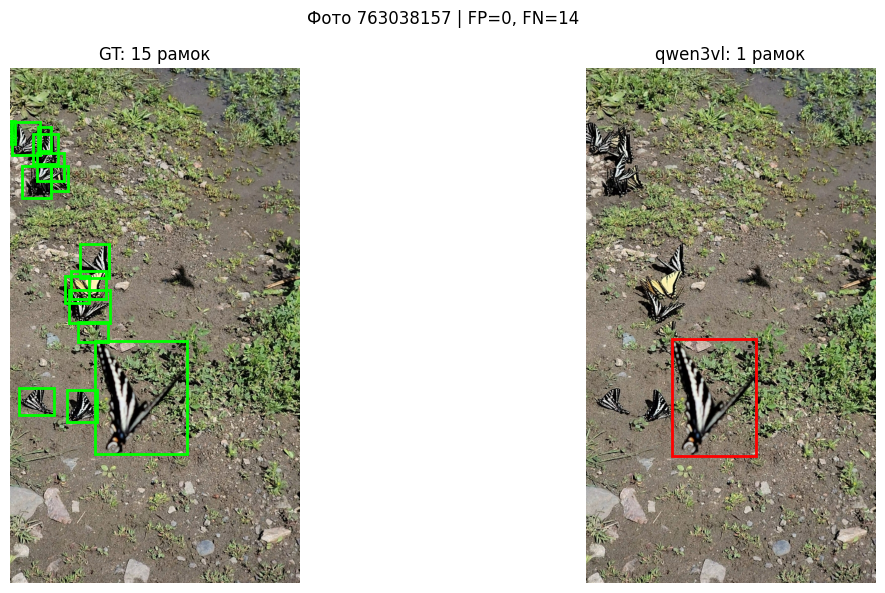

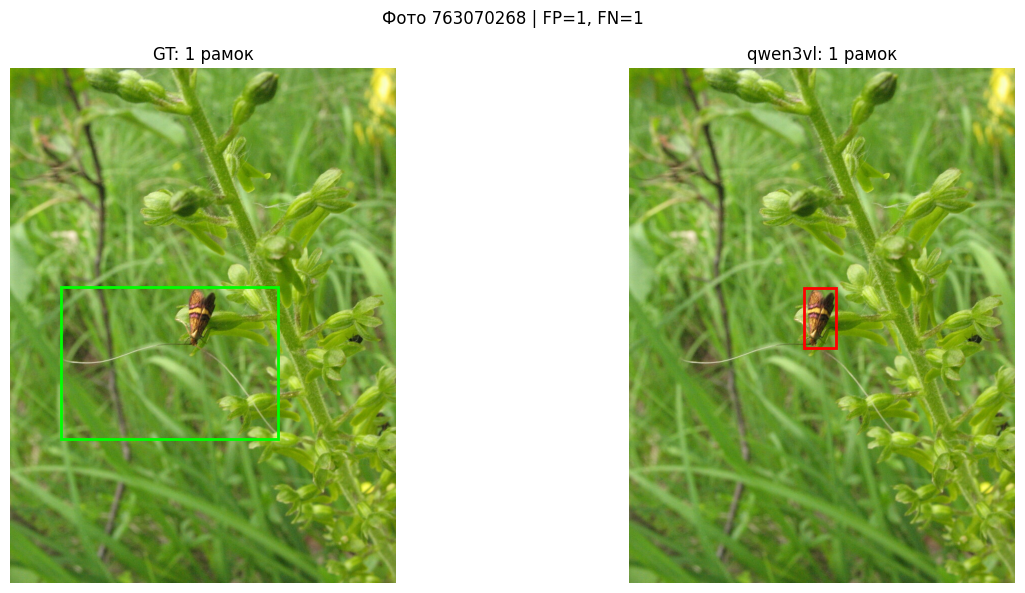

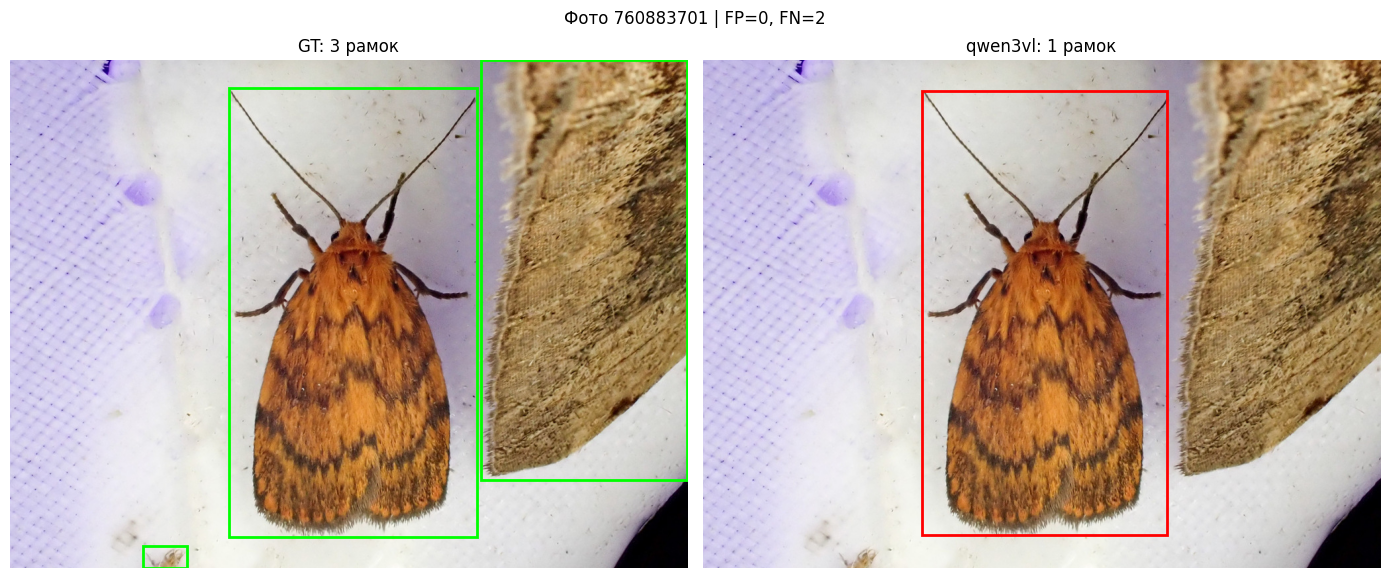

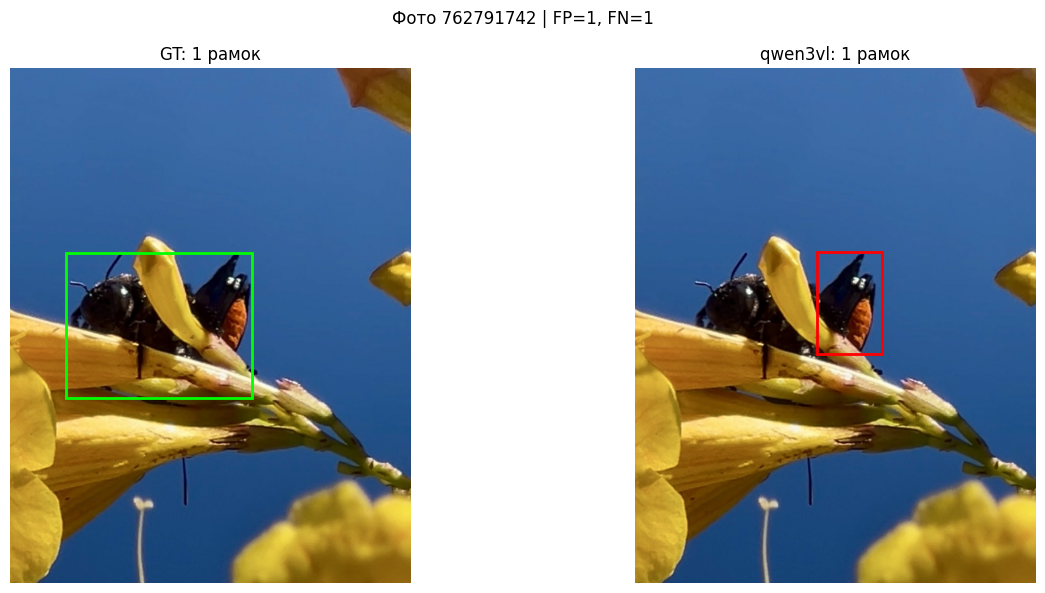

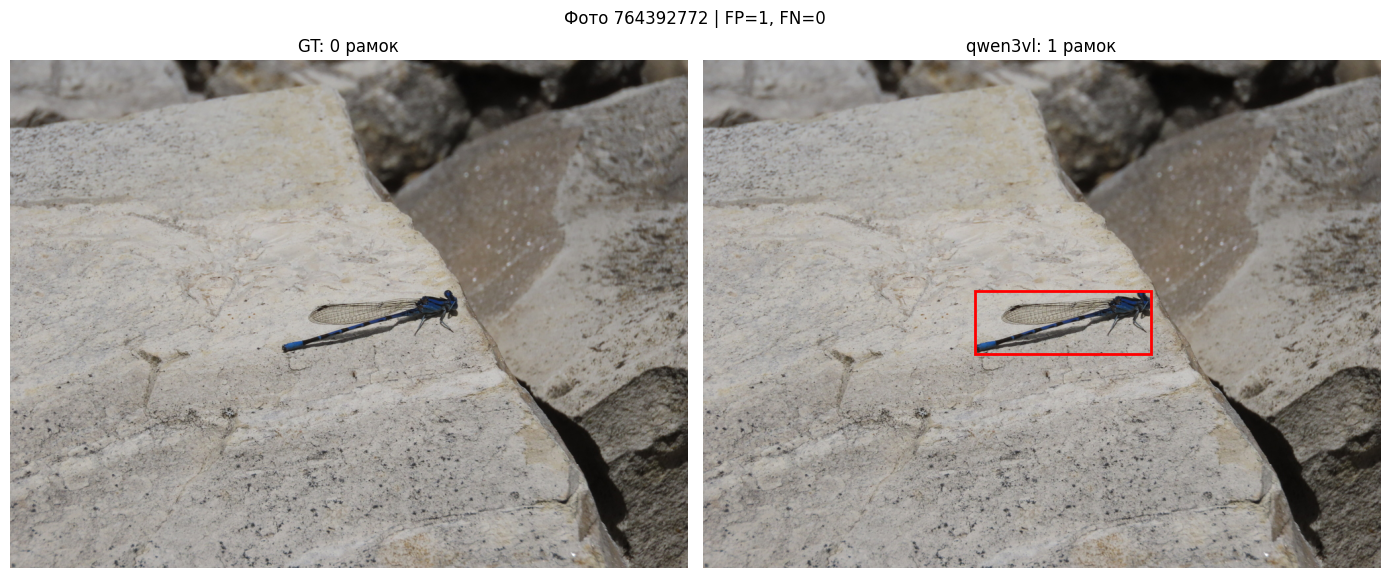

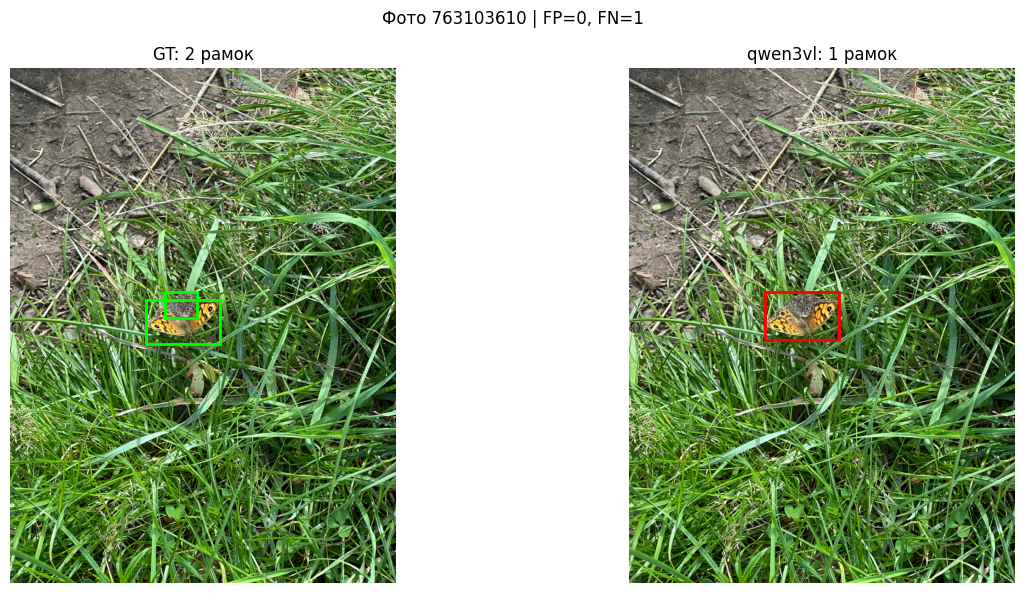

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

MODEL_TO_VIEW = 'qwen3vl'
ONLY_ERRORS = True
START = 0
COUNT = 6

predictions = {r['photo_id']: r for r in read_jsonl(RESULT_DIR / f'{MODEL_TO_VIEW}_predictions.jsonl')}
to_show = []
for row in rows:
    pred = predictions[row['photo_id']]
    fp = fn = 0
    if DATASET == 'ground_truth':
        _, fp, fn = counts(row['boxes'], pred['boxes'])
    if DATASET == 'exam' or not ONLY_ERRORS or fp + fn > 0:
        to_show.append((row, pred, fp, fn))
if DATASET == 'ground_truth':
    to_show.sort(key=lambda x: x[2] + x[3], reverse=True)

for row, pred, fp, fn in to_show[START:START + COUNT]:
    image = load_image(row)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    boxes_to_draw = [row['boxes'] if DATASET == 'ground_truth' else [], pred['boxes']]
    titles = ['GT' if DATASET == 'ground_truth' else 'image', MODEL_TO_VIEW]
    for ax, boxes, title, color in zip(axes, boxes_to_draw, titles, ['lime', 'red']):
        ax.imshow(image)
        for box in boxes:
            ax.add_patch(Rectangle(
                (box['left'] * image.width, box['top'] * image.height),
                box['width'] * image.width, box['height'] * image.height,
                fill=False, edgecolor=color, linewidth=2))
        ax.set_title(f'{title}: {len(boxes)} рамок')
        ax.axis('off')
    title = f"Фото {row['photo_id']}"
    if DATASET == 'ground_truth':
        title += f' | FP={fp}, FN={fn}'
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
